In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import os
import tarfile
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

# Mount Google Drive to access your files directly
from google.colab import drive
drive.mount('/content/drive')

# Define the path to your dataset in your Google Drive
# e.g., if MyDataset.tgz is in the root of your My Drive:
drive_dataset_path = "/content/drive/MyDrive/MyDataset.tgz"
extract_path = "/content/MyDataset_extracted"

# Extract the dataset
if os.path.exists(drive_dataset_path):
    print("Extracting dataset...")
    with tarfile.open(drive_dataset_path, "r:gz") as tar:
        tar.extractall(path=extract_path)
    print("Extraction complete!")
    print("Contents:", os.listdir(extract_path))
else:
    print(f"Could not find dataset at: {drive_dataset_path}")
    print("Please verify that the file exists and is located in the correct folder in Google Drive.")

# Extraction of Test Dataset
drive_testdataset_path = "/content/drive/MyDrive/TestDataset.tgz"
test_extract_path = "/content/TestDataset_extracted"

# Extract the dataset if it exists
if os.path.exists(drive_testdataset_path):
    print("Extracting dataset...")
    with tarfile.open(drive_testdataset_path, "r:gz") as tar:
        tar.extractall(path=test_extract_path)
    print("Extraction complete!")
    print("Contents:", os.listdir(test_extract_path))
else:
    print(f"Could not find dataset at: {drive_testdataset_path}")
    print("Please verify that the file exists and is located in the correct folder in Google Drive.")

img_size = (128, 128)
batch_size = 32

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting dataset...


/tmp/ipykernel_1204/3066827817.py:23: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Extraction complete!
Contents: ['MyDataset']
Extracting dataset...


/tmp/ipykernel_1204/3066827817.py:38: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=test_extract_path)


Extraction complete!
Contents: ['TestDataset']


In [ ]:
import os
import glob

dataset_path = "/content/MyDataset_extracted/MyDataset"
test_dataset_path = "/content/TestDataset_extracted/TestDataset"

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.2,
    subset="training",
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(

    test_dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.2,
    subset="validation",
    seed=42
)

class_names = train_ds.class_names
print("Classes found:", class_names)

Found 10000 files belonging to 10 classes.
Using 8000 files for training.
Found 10000 files belonging to 10 classes.
Using 2000 files for validation.
Classes found: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


In [ ]:
classes = os.listdir(dataset_path)

for class_name in classes:
    class_dir = os.path.join(dataset_path, class_name)
    if os.path.isdir(class_dir):
        # Count all files inside the subfolder
        image_count = len(glob.glob(os.path.join(class_dir, "*")))
        print(f"Class '{class_name}': {image_count} images")

Class 'Tomato___Target_Spot': 1000 images
Class 'Tomato___Leaf_Mold': 1000 images
Class 'Tomato___Septoria_leaf_spot': 1000 images
Class 'Tomato___healthy': 1000 images
Class 'Tomato___Spider_mites Two-spotted_spider_mite': 1000 images
Class 'Tomato___Bacterial_spot': 1000 images
Class 'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 1000 images
Class 'Tomato___Late_blight': 1000 images
Class 'Tomato___Early_blight': 1000 images
Class 'Tomato___Tomato_mosaic_virus': 1000 images


In [ ]:
# 1. Build the model
num_classes = len(class_names)

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax") # Correctly set to 10 classes
])

# 2. Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
'''
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",        # Stops training when validation loss stops improving
    patience=3,                # Number of epochs to wait for improvement before stopping
    restore_best_weights=True  # Keeps the model weights from the epoch with the best val_loss
)
'''
# 3. Fit the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
    #callbacks=[early_stopping]
)

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 273s 1s/step - accuracy: 0.2878 - loss: 3.8511 - val_accuracy: 0.4495 - val_loss: 1.5416
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 262s 1s/step - accuracy: 0.4924 - loss: 1.4833 - val_accuracy: 0.6085 - val_loss: 1.1132
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 257s 1s/step - accuracy: 0.6434 - loss: 1.0535 - val_accuracy: 0.7325 - val_loss: 0.7472
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 256s 1s/step - accuracy: 0.7095 - loss: 0.8404 - val_accuracy: 0.7820 - val_loss: 0.6548
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.7742 - loss: 0.6692 - val_accuracy: 0.7345 - val_loss: 0.7565
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 260s 1s/step - accuracy: 0.8010 - loss: 0.6038 - val_accuracy: 0.8120 - val_loss: 0.5770
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 257s 1s/step - accuracy: 0.8349 - loss: 0.4882 - val_accuracy: 0.8225 - val_loss: 0.5603
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 258s 1s/step - accuracy: 0.8375 - loss: 0.4816 - val_accu

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
Predicted Disease: Tomato___Target_Spot
Confidence: 90.38649

Remedy: Use beneficial microbes like Trichoderma (such as Trichoderma harzianum) applied to the soil and use Neem Oil


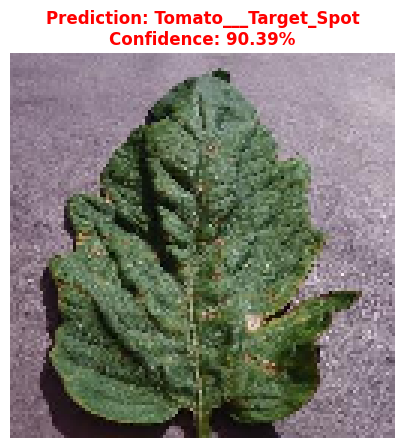

In [ ]:
# Prediction of Plant Disease
import matplotlib.pyplot as plt

img = load_img(
    "Sample4.JPG",
    target_size=(128, 128)
)
img_array = img_to_array(img)
img_array = np.expand_dims(
    img_array,
    axis=0
)
prediction = model.predict(img_array)
predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

# Eco Friendly Organic Remedy
print("Predicted Disease:", predicted_class)
print("Confidence:", confidence)
if predicted_class == "Tomato___Bacterial_spot":
  print("\nRemedy:\nCopper-Based Fungicides / Bactericides")
if predicted_class == "Tomato___Septoria_leaf_spot":
  print("\nRemedy: Use Neem Oil")
if predicted_class == "Tomato___Tomato_mosaic_virus":
  print("\nRemedy:Use Trichoderma viride and Pseudomonas fluorescens in the root/seed zone")
if predicted_class == "Tomato___Late_blight":
  print("Remedy: Natural extracts like aloe vera extract, garlic extract, turmeric, and neem oil can help suppress disease ")
if predicted_class == "Tomato___Early_blight":
  print("\nRemedy: Use Copper-Based Fungicides, Bacillus subtilis,Neem Oil")
if predicted_class == "Tomato___Target_Spot":
  print("\nRemedy: Use beneficial microbes like Trichoderma (such as Trichoderma harzianum) applied to the soil and use Neem Oil")
if predicted_class == "Tomato___Tomato_Yellow_Leaf_Curl_Virus":
  print("\nRemedy:Use Neem Oil Spray, Yellow Sticky Traps to control white flies or \n use Neem Leaf Extract or mustard oil cake extracts")
if predicted_class == "Tomato___Spider_mites Two-spotted_spider_mite":
  print("\nRemedy: Use Neem Oil, Water Blast, Pruning, Increase Humidity or use Phytoseiulus persimilis or Neoseiulus longispinosus")
if predicted_class == "Tomato___Leaf_Mold":
  print("\n Remedy: Use Copper hydroxide or sulfur-based fungicides ")
if predicted_class == "Tomato___healthy":
  print("\nRemedy: Healthy Plant")

# Display the test image with its prediction details
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis('off')

# Format the title with the predicted class name and confidence score
title_text = f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%"
plt.title(title_text, fontsize=12, fontweight='bold', color='green' if 'healthy' in predicted_class else 'red')

plt.show()

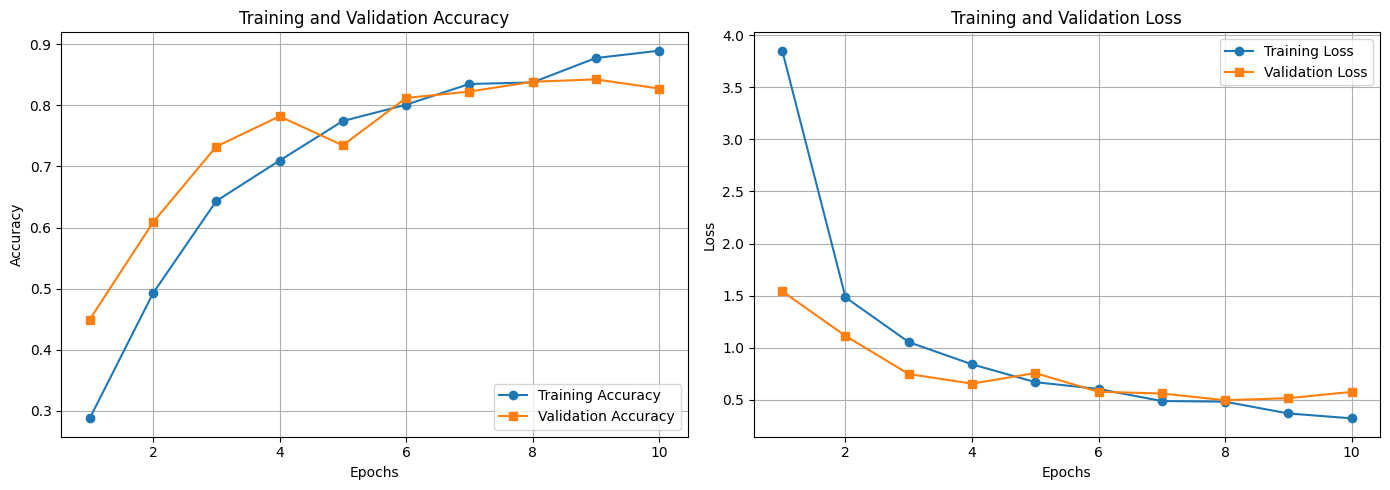

In [ ]:
import matplotlib.pyplot as plt

# Retrieve training metrics from the history object
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# Create a figure for side-by-side plots
plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='s')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='s')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()